# NYC Airbnb listing comparisons
## Business question and data scope
How do listed prices, room types and calendar availability vary in the project's historical NYC listing dataset?

The original analysis source contained 38,185 rows. Source-level preparation removed duplicate listing IDs, invalid/nonpositive prices and availability values outside 0–365, retaining 38,149 records. The source collection date was not documented. The public notebook uses borough-level and citywide room-type aggregates: no individual listings, host identities, coordinates or private-source identifiers are distributed.

These extracts reproduce the descriptive charts. Rebuilding source-level cleaning requires the original dataset supplied locally; it is not bundled. The filters are recorded here for transparency, and counts refer to the historical project snapshot rather than current inventory.


In [1]:
from pathlib import Path
from urllib.request import urlopen
import io
import pandas as pd
import matplotlib.pyplot as plt
BASE="https://anjanasriya20-alt.github.io/Anjana-Sriya-/data/"
def load(name):
    local=Path("data")/name
    if local.exists(): return pd.read_csv(local)
    with urlopen(BASE+name,timeout=30) as response:
        return pd.read_csv(io.BytesIO(response.read()))
borough=load("nyc-borough-summary.csv")
roomtype=load("nyc-roomtype-summary.csv")
assert borough.listings.sum()==roomtype.listings.sum()
assert borough.listings.gt(0).all() and roomtype.listings.gt(0).all()
assert borough.median_price.gt(0).all()
assert borough.median_available_days.between(0,365).all()
print("Filtered records represented:",borough.listings.sum())
print(borough.round(2).to_string(index=False))
print(roomtype.round(2).to_string(index=False))


Filtered records represented: 38149
neighbourhood_group  listings  median_price  median_available_days
              Bronx      1125          75.0                  180.0
           Brooklyn     14678          98.0                   64.0
          Manhattan     16575         139.0                   83.0
             Queens      5431          75.0                  137.0
      Staten Island       340          89.0                  179.5
      room_type  listings  median_price  median_available_days
Entire home/apt     20376         150.0                   88.0
     Hotel room       173         184.0                  337.0
   Private room     17034          67.0                   83.0
    Shared room       566          50.0                  127.0


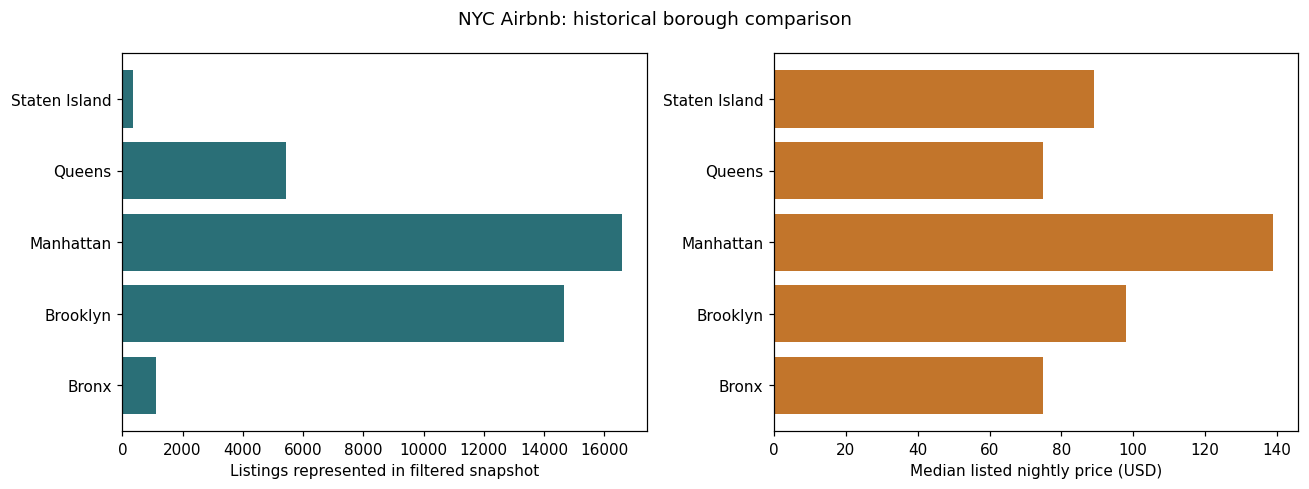

In [2]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].barh(borough.neighbourhood_group,borough.listings,color="#2A6F77")
axes[0].set_xlabel("Listings represented in filtered snapshot")
axes[1].barh(borough.neighbourhood_group,borough.median_price,color="#C2752B")
axes[1].set_xlabel("Median listed nightly price (USD)")
fig.suptitle("NYC Airbnb: historical borough comparison")
plt.tight_layout();plt.show()


## Interpretation and limits
The aggregates support descriptive comparisons of asking prices and listing availability. Differences in room type and property mix can affect borough-level medians. They do not establish that a neighborhood is underpriced, that low listing counts imply unmet demand, or that changing a price would change bookings.

Unavailable dates are not observed bookings: hosts can block their calendars. We do not infer occupancy, demand or revenue as 365 minus available days. A single cross-sectional snapshot cannot establish seasonality or causal effects. Source methodology: https://insideairbnb.com/data-assumptions/.

The analysis is historical and uses aggregated extracts; source-level reproducibility requires the original project dataset and the documented filters. No restricted-source URL or individual listing data are published in this refresh.
